# Contesto
Un cliente della Nurra ha 8 particelle, e il suo agronomo vuole sapere quali andare a controllare in campo questa settimana. Vengono forniti due file, simulati ma con la stessa struttura di quelli veri:
- particelle_azienda.geojson: i confini delle 8 particelle, esportati dall'app aziendale, con id_particella, coltura e superficie_dichiarata_ha
- ndvi_2025-06-20.tif: l'NDVI calcolato da Sentinel-2 il 20 giugno 2025, con una risoluzione di 10 m

# Obiettivo
Produrre una tabella contenente, per ogni particella:
- NDVI medio
- % di superficie con NDVI sotto 0.4
- % di superficie coperta da nuvole
- Controllo della superficie dichiarata

# 1. ===================== CARICARE ED ESPLORARE IL DATASET =====================

In [1]:
# Import librerie
import pandas as pd
import numpy as np
import geopandas as gpd 
import rasterio 
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask

In [2]:
# Caricare i file
particelle = gpd.read_file("dati/particelle_azienda.geojson")
ndvi = rasterio.open("dati/ndvi_2025-06-20.tif")

In [3]:
# Ispezionare la tabella particelle
particelle.head()

,id_particella,coltura,superficie_dichiarata_ha,geometry
0,P01,mais,15.76,"POLYGON ((8.33867 40.62143, 8.34363 40.6215, 8..."
1,P02,mais,13.39,"POLYGON ((8.34411 40.62146, 8.3486 40.6214, 8...."
2,P03,grano duro,15.32,"POLYGON ((8.34919 40.62158, 8.35498 40.62157, ..."
3,P04,vite,8.91,"POLYGON ((8.33871 40.61747, 8.34272 40.61758, ..."
4,P05,vite,7.98,"POLYGON ((8.3432 40.61767, 8.34627 40.61778, 8..."


In [4]:
# Ispezionare il CRS della tabella particelle
print("============ PARTICELLE ============")
particelle.crs

============ PARTICELLE ============


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
# Ispezionare il CRS del raster (ndvi)
print("============ RASTER NDVI ============")
print("CRS raster:")
print(ndvi.crs.to_epsg())

# Ispezionare la dimensione dei pixel del raster
print("Dimensione dei pixel:")
print(ndvi.res)

# Ispezionare il valore usato per i pixel senza dato
print("Valore corrispondente ai pixel nodata:")
print(ndvi.nodata)

============ RASTER NDVI ============
CRS raster:
32632
Dimensione dei pixel:
(10.0, 10.0)
Valore corrispondente ai pixel nodata:
-9999.0


# 2. ===================== RIPROIEZIONE E CONTROLLO DELLE SUPERFICI =====================

In [6]:
# Riproiettare i poligoni nel CRS del file raster (EPSG 32632)
particelle_utm = particelle.to_crs(ndvi.crs)

# Calcolare la superficie per appezzamento in ettari
particelle_utm["superficie_calcolata_ha"] = (particelle_utm.geometry.area / 10000).round(2)
particelle_utm = particelle_utm[["id_particella", "coltura", "superficie_dichiarata_ha", "superficie_calcolata_ha", "geometry"]]
particelle_utm

,id_particella,coltura,superficie_dichiarata_ha,superficie_calcolata_ha,geometry
0,P01,mais,15.76,15.75,"POLYGON ((444063.703 4496943.698, 444483.704 4..."
1,P02,mais,13.39,13.95,"POLYGON ((444523.701 4496943.696, 444903.699 4..."
2,P03,grano duro,15.32,15.96,"POLYGON ((444953.702 4496953.703, 445443.698 4..."
3,P04,vite,8.91,8.91,"POLYGON ((444063.696 4496503.7, 444403.701 449..."
4,P05,vite,7.98,7.98,"POLYGON ((444443.703 4496523.7, 444703.701 449..."
5,P06,carciofo,8.32,8.32,"POLYGON ((444763.701 4496533.697, 445103.703 4..."
6,P07,erba medica,17.71,15.81,"POLYGON ((445153.7 4496563.705, 445453.697 449..."
7,P08,oliveto,15.45,15.45,"POLYGON ((444063.702 4496183.704, 445083.696 4..."


# La tabella delle particelle prodotta evidenzia come la superficie calcolata in ettari per la particella P07 sia in realtà più piccola di circa 1.9 ettari rispetto alla superficie dichiarata, mentre le particelle P02 e P03 sono leggermente più grandi della superficie dichiarata, rispettivamente di 0.56 ettari e 0.64 ettari.

# 3. ===================== ESPLORAZIONE DEL RASTER =====================

In [7]:
# Leggere il raster come tabella
valori = ndvi.read(1)

# Contare i pixel senza dato nel raster
pixel_no_data = (valori == ndvi.nodata).sum()
print("Pixel senza dato nel raster:")
print(pixel_no_data)

Pixel senza dato nel raster:
448


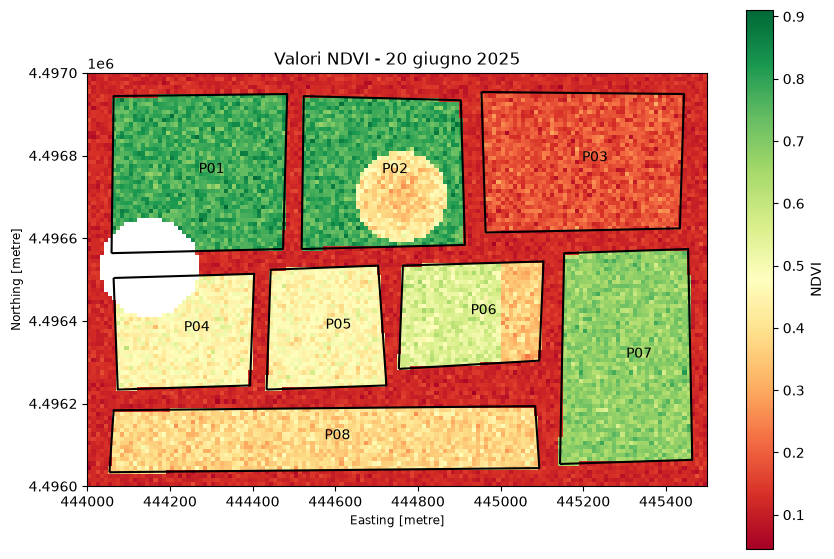

In [8]:
# Caricare ed esportare l'immagine del raster con i confini delle particelle
# I pixel senza dato vengono visualizzati con il colore bianco
fig, ax = plt.subplots(figsize=(10, 7))

immagine = ax.imshow(np.where(valori == ndvi.nodata, np.nan, valori), cmap="RdYlGn", 
          extent=[ndvi.bounds.left, ndvi.bounds.right, ndvi.bounds.bottom, ndvi.bounds.top])
fig.colorbar(immagine, ax=ax, label="NDVI")
particelle_utm.boundary.plot(ax=ax, color="black")

for indice, riga in particelle_utm.iterrows():
    ax.text(riga.geometry.centroid.x, riga.geometry.centroid.y, riga["id_particella"])
plt.title("Valori NDVI - 20 giugno 2025")
plt.savefig("mappa_ndvi.png", dpi = 150, bbox_inches="tight")
plt.show()

# L'esplorazione del raster evidenzia la presenza di 448 pixel senza dato, che corrispondono a una nuvola sopra le particelle P01 e P04.

# 4. ===================== ANALIZZARE L'EFFETTO DELLE NUVOLE SULLA PARTICELLA P04  ===================== 

In [9]:
# Recuperare la geometria della particella P04
geom_p04 = particelle_utm.loc[particelle_utm["id_particella"] == "P04", "geometry"].iloc[0]
pixel_p04 = valori[geometry_mask([geom_p04], out_shape=valori.shape, transform=ndvi.transform, invert=True)]

# Calcolare l'NDVI medio
print("NDVI medio di P04 senza escludere le nuvole:")
print(pixel_p04.mean())

NDVI medio di P04 senza escludere le nuvole:
-1783.9551


# Calcolando l'NDVI medio della particella P04 includendo i pixel senza dato (-9999), la media di P04 risulta -1785, un valore impossibile per l'NDVI. Nella funzione i pixel nuvolosi verranno quindi contati a parte ed esclusi dai calcoli.

# 5. ===================== CALCOLARE NDVI MEDIO, % NUVOLE E % NDVI SOTTO LA SOGLIA DI 0.4  ===================== 

In [10]:
# Definire una funzione per il calcolo delle statistiche NDVI per ogni appezzamento
def statistiche_ndvi(geometria):
    dentro = geometry_mask([geometria], out_shape=valori.shape, transform=ndvi.transform, invert=True)
    pixel = valori[dentro]
    percentuale_nuvole = (((pixel == ndvi.nodata).sum() / len(pixel)) * 100).round(2)
    pixel_validi = pixel[pixel != ndvi.nodata]
    ndvi_medio = pixel_validi.mean().round(3)
    perc_ndvi_sotto_04 = (((pixel_validi < 0.4).sum()) / len(pixel_validi) * 100).round(2)

    return {
        "perc_nuvole": percentuale_nuvole,
        "ndvi_medio": ndvi_medio,
        "perc_sotto_04": perc_ndvi_sotto_04
    }

# Applicare la funzione a tutte le particelle
risultati = []

for indice, riga in particelle_utm.iterrows():
    statistiche = statistiche_ndvi(riga["geometry"])
    statistiche["id_particella"] = riga["id_particella"]
    risultati.append(statistiche)


# Trasformare la lista risultati in una tabella
stat_ndvi = pd.DataFrame(risultati)

# Unire la tabella delle statistiche NDVI con la tabella delle particelle
report_ndvi = pd.merge(particelle_utm, stat_ndvi, on="id_particella", how="left")
report_ndvi = report_ndvi[["id_particella", "coltura", "superficie_dichiarata_ha", "superficie_calcolata_ha", "perc_nuvole", "ndvi_medio", "perc_sotto_04", "geometry"]]
report_ndvi

,id_particella,coltura,superficie_dichiarata_ha,superficie_calcolata_ha,perc_nuvole,ndvi_medio,perc_sotto_04,geometry
0,P01,mais,15.76,15.75,8.20,0.780,0.00,"POLYGON ((444063.703 4496943.698, 444483.704 4..."
1,P02,mais,13.39,13.95,0.00,0.676,13.80,"POLYGON ((444523.701 4496943.696, 444903.699 4..."
2,P03,grano duro,15.32,15.96,0.00,0.180,100.00,"POLYGON ((444953.702 4496953.703, 445443.698 4..."
3,P04,vite,8.91,8.91,17.85,0.460,6.83,"POLYGON ((444063.696 4496503.7, 444403.701 449..."
4,P05,vite,7.98,7.98,0.00,0.459,6.65,"POLYGON ((444443.703 4496523.7, 444703.701 449..."
5,P06,carciofo,8.32,8.32,0.00,0.494,24.61,"POLYGON ((444763.701 4496533.697, 445103.703 4..."
6,P07,erba medica,17.71,15.81,0.00,0.678,0.00,"POLYGON ((445153.7 4496563.705, 445453.697 449..."
7,P08,oliveto,15.45,15.45,0.00,0.380,69.49,"POLYGON ((444063.702 4496183.704, 445083.696 4..."


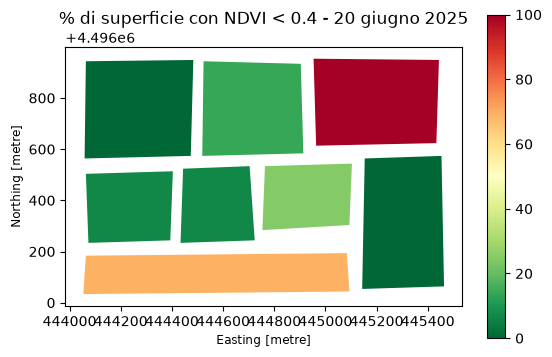

In [11]:
# Salvare ed esportare il report finale 
report_ndvi.to_file("report_NDVI.gpkg")

# Salvare ed esportare il report in csv senza geometrie
report_ndvi_no_geom = report_ndvi.drop(columns="geometry")
report_ndvi_no_geom.to_csv("report_NDVI.csv", index=False)

# Salvare ed esportare la mappa finale
report_ndvi.plot(column="perc_sotto_04", cmap="RdYlGn_r", legend=True)
plt.title("% di superficie con NDVI < 0.4 - 20 giugno 2025")
plt.savefig("mappa_stress.png", dpi = 150, bbox_inches="tight")
plt.show()

# Interpretazione
Il report finale evidenzia un'alta percentuale di valori NDVI al di sotto della soglia stabilita di 0,4 per le seguenti particelle: 
- P03: coltivata a grano duro che viene trebbiato nel mese di giugno, giustificando così l'alto valore rilevato (100%).
- P06: coltivata a carciofo, che nel mese di giugno si trova in fase di riposo (24,6%).
- P08: un oliveto tipicamente caratterizzato da chiome rade e ampi spazi vuoti tra gli alberi (69,5%).
- P02: coltivata a mais, presenta un valore di 13,8%. Di contro l'appezzamento P01, sempre coltivato a mais presenta un valore di 0%. Per questa coltura a fine giugno, sono attesi valori di NDVI alti e uniformi. In aggiunta, i valori bassi sono concentrati in una zona, quindi fanno pensare a un problema localizzato (irrigazione, parassiti, ristagno).

# Raccomandazioni
- È consigliato controllare immediatamente la particella P02 di mais che mostra valori anomali di NDVI. 
- Ricontrollare con la prossima immagine senza nuvole la particella P04, dato che l'immagine utilizzata per l'analisi ha una copertura di nuvole del 17,8%.
- Da segnalare la particella P07 che presenta 1,9 ha dichiarati in più di quelli misurati (circa +12%).
- Non sono stati rilevati problemi per le particelle P03, P06 e P08, dove i valori NDVI bassi sono normali per la coltura e il periodo.